# 02 Dimensiereductie en clustering

**Workshops:** LU2 `02_Demo PCA, t-SNE, UMAP`, `03_Opdracht Dimensionality Reduction` en het K-means deel van `04`.

**Doel:** zien of het leesmateriaal natuurlijke groepen vormt als we tekst en kenmerken combineren, en of studenten
in herkenbare groepen (segmenten) vallen. Dat helpt bij het uitleggen van het model en bij het controleren op eenzijdige advies.

In [1]:
import sys
from pathlib import Path

# Make the project package importable, also without "pip install -e ."
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from leescoach import config

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
from leescoach.content import ContentModel
from leescoach.data_cleaning import load_processed

materials, students, interactions = load_processed()
content = ContentModel().fit(materials)
print("TF-IDF matrix:", content.matrix.shape, "(materialen x woorden)")

TF-IDF matrix: (275, 3639) (materialen x woorden)


## 1. Kenmerken voorbereiden
We combineren de TF-IDF tekstvectoren (eerst teruggebracht met TruncatedSVD, want PCA werkt niet op sparse matrices) met geschaalde numerieke kenmerken. Schalen is nodig omdat PCA, t-SNE en UMAP met afstanden werken.

In [3]:
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.preprocessing import StandardScaler

text_part = TruncatedSVD(n_components=30, random_state=config.RANDOM_STATE).fit_transform(content.matrix)
numeric_part = StandardScaler().fit_transform(
    materials[["niveau_num", "aantal_paginas", "geschatte_leestijd_min", "leescomplexiteit_score", "gem_woordlengte", "aandeel_lange_woorden_pct"]]
)
X = np.hstack([StandardScaler().fit_transform(text_part), numeric_part])
print(X.shape)

(275, 36)


## 2. PCA

Verklaarde variantie per component: [0.11  0.056]
Totaal: 0.166


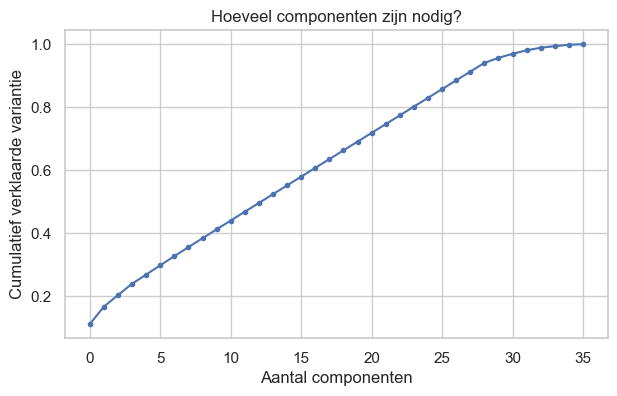

In [4]:
pca = PCA(n_components=2, random_state=config.RANDOM_STATE)
X_pca = pca.fit_transform(X)
print("Verklaarde variantie per component:", pca.explained_variance_ratio_.round(3))
print("Totaal:", pca.explained_variance_ratio_.sum().round(3))

full = PCA().fit(X)
plt.figure(figsize=(7, 4))
plt.plot(np.cumsum(full.explained_variance_ratio_), marker=".")
plt.xlabel("Aantal componenten")
plt.ylabel("Cumulatief verklaarde variantie")
plt.title("Hoeveel componenten zijn nodig?")
plt.show()

## 3. t-SNE en UMAP

In [5]:
from sklearn.manifold import TSNE

X_tsne = TSNE(n_components=2, perplexity=30, random_state=config.RANDOM_STATE).fit_transform(X)
try:
    import warnings
    import umap

    warnings.filterwarnings("ignore", category=FutureWarning, module="umap")
    warnings.filterwarnings("ignore", category=UserWarning, module="umap")
    X_umap = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=config.RANDOM_STATE).fit_transform(X)
except ImportError:
    X_umap = None
    print("umap-learn is niet geinstalleerd: pip install umap-learn")

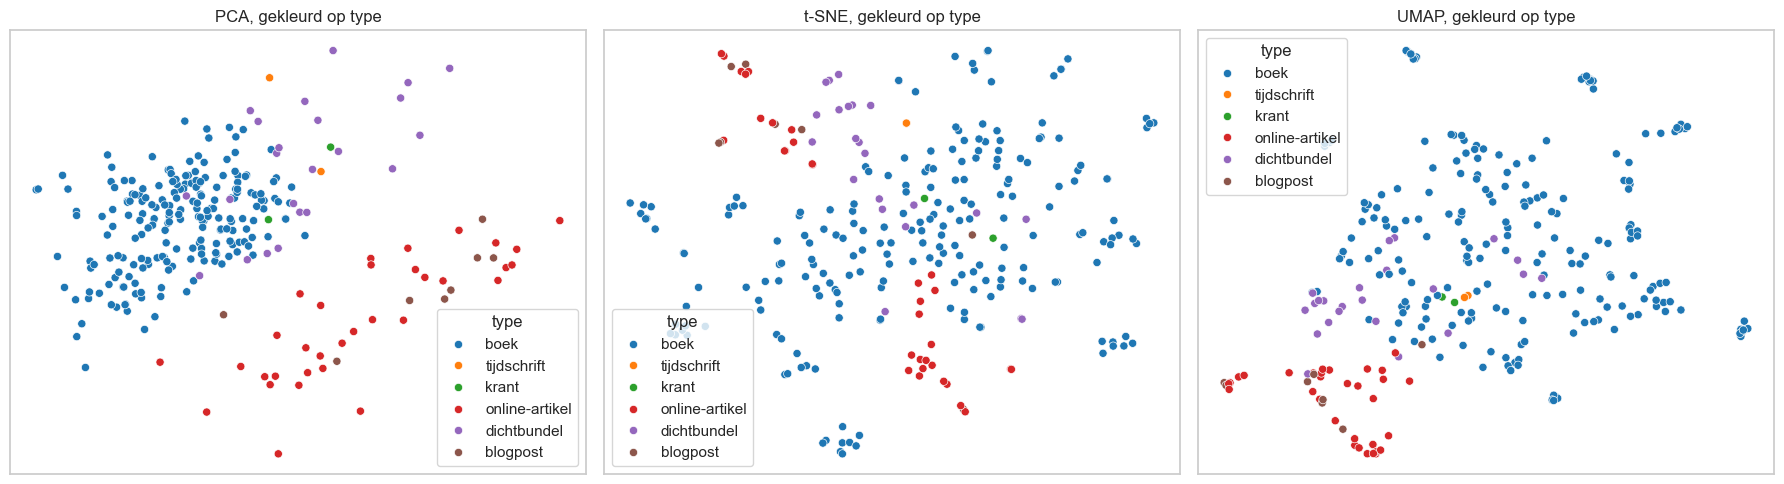

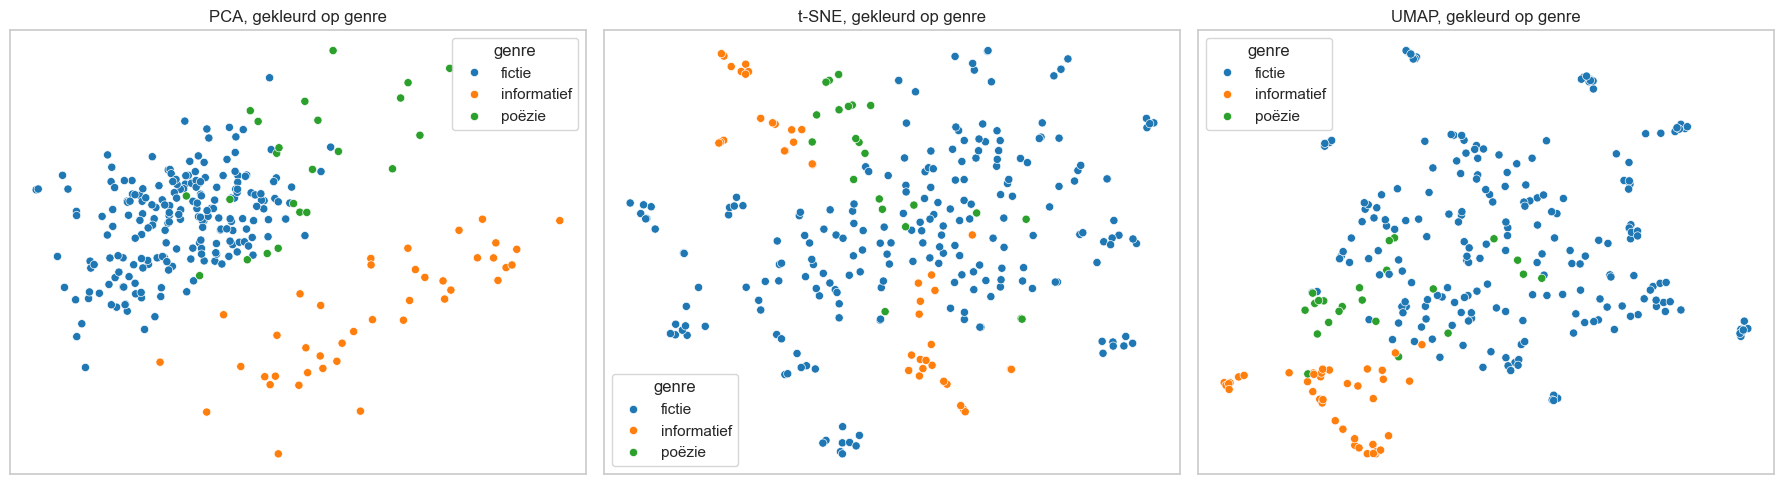

In [6]:
projections = {"PCA": X_pca, "t-SNE": X_tsne}
if X_umap is not None:
    projections["UMAP"] = X_umap

for colour in ["type", "genre"]:
    fig, axes = plt.subplots(1, len(projections), figsize=(6 * len(projections), 5))
    for ax, (name, points) in zip(axes, projections.items()):
        sns.scatterplot(x=points[:, 0], y=points[:, 1], hue=materials[colour], ax=ax, s=35, palette="tab10")
        ax.set_title(f"{name}, gekleurd op {colour}")
        ax.set_xticks([]); ax.set_yticks([])
    plt.tight_layout()
    plt.savefig(config.FIGURES_DIR / f"02_projecties_{colour}.png", dpi=120)
    plt.show()

## 4. Experiment met parameters (opdracht stap 4)

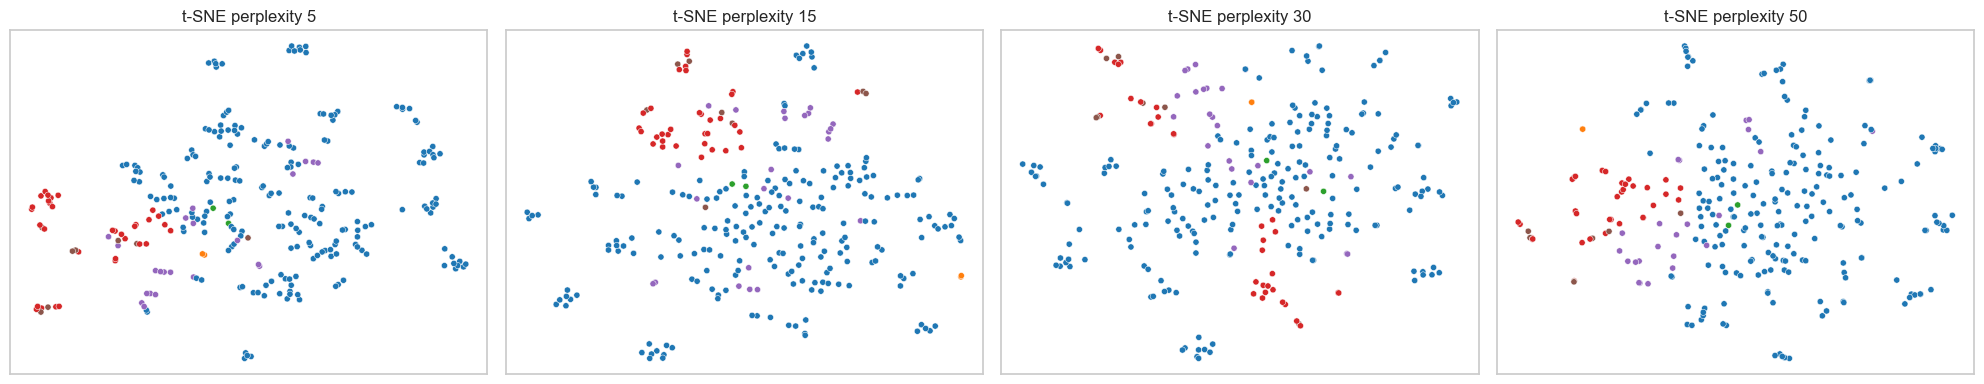

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, perplexity in zip(axes, [5, 15, 30, 50]):
    points = TSNE(n_components=2, perplexity=perplexity, random_state=config.RANDOM_STATE).fit_transform(X)
    sns.scatterplot(x=points[:, 0], y=points[:, 1], hue=materials["type"], ax=ax, s=20, legend=False, palette="tab10")
    ax.set_title(f"t-SNE perplexity {perplexity}")
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

## 5. K-means: studentsegmenten
We beschrijven elke student met zijn niveau, maximale leestijd en interesses (one hot) en zoeken groepen. De silhouette score helpt bij het kiezen van het aantal clusters.

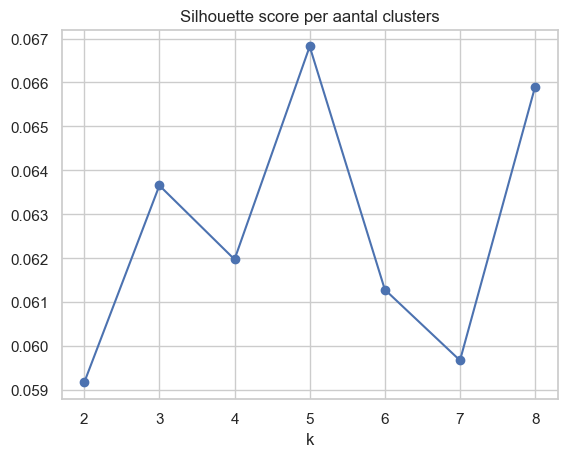

Beste k: 5 score 0.067


In [8]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

interest_dummies = students["interesses"].str.get_dummies(sep=";")
profile = pd.concat([
    students[["leesniveau_num", "taalniveau_num", "max_leestijd_min"]],
    pd.get_dummies(students[["voorkeur_materiaaltype", "voorkeur_genre"]]).astype(int),
    interest_dummies,
], axis=1)
profile_scaled = StandardScaler().fit_transform(profile)

scores = {}
for k in range(2, 9):
    labels = KMeans(n_clusters=k, n_init=10, random_state=config.RANDOM_STATE).fit_predict(profile_scaled)
    scores[k] = silhouette_score(profile_scaled, labels)
pd.Series(scores, name="silhouette").plot(marker="o", title="Silhouette score per aantal clusters")
plt.xlabel("k"); plt.show()
best_k = max(scores, key=scores.get)
print("Beste k:", best_k, "score", round(scores[best_k], 3))

In [9]:
kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=config.RANDOM_STATE)
students["segment"] = kmeans.fit_predict(profile_scaled)
summary = students.groupby("segment").agg(
    aantal=("student_id", "size"),
    leesniveau=("leesniveau", lambda s: s.mode().iat[0]),
    materiaaltype=("voorkeur_materiaaltype", lambda s: s.mode().iat[0]),
    genre=("voorkeur_genre", lambda s: s.mode().iat[0]),
    max_leestijd=("max_leestijd_min", "median"),
)
summary["top_interesses"] = [
    ", ".join(interest_dummies[students["segment"] == segment].sum().nlargest(3).index) for segment in summary.index
]
summary

,aantal,leesniveau,materiaaltype,genre,max_leestijd,top_interesses
segment,,,,,,
0,22,2F,online artikel,poëzie,45.0,"humor, vriendschap, sport"
1,24,2F,online artikel,geen voorkeur,60.0,"persoonlijke ontwikkeling, reizen, klimaat"
2,11,2F,online artikel,fictie,30.0,"technologie, politiek, humor"
3,17,3F,boek,informatief,30.0,"kunstmatige intelligentie, relaties, natuur"
4,26,2F,gemengd,fictie,37.5,"reizen, cultuur, geschiedenis"


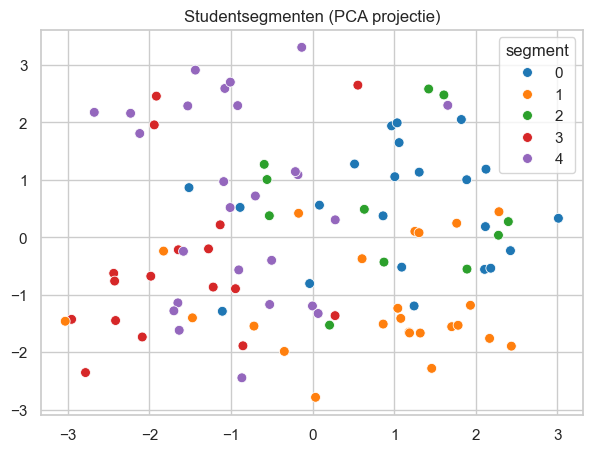

In [10]:
points = PCA(n_components=2, random_state=config.RANDOM_STATE).fit_transform(profile_scaled)
plt.figure(figsize=(7, 5))
sns.scatterplot(x=points[:, 0], y=points[:, 1], hue=students["segment"], palette="tab10", s=50)
plt.title("Studentsegmenten (PCA projectie)")
plt.show()

## Interpretatie (vul aan met jullie eigen observaties)

1. **Verschil tussen de technieken:** PCA is lineair en houdt de grote lijnen (variantie) vast; t-SNE laat vooral lokale
   buren zien; UMAP zit ertussen en is sneller.
2. **Welke laat groepen het best zien?** Kijk of de types (boek tegenover artikel en blogpost) en genres als losse wolken verschijnen.
3. **Hoeveel informatie blijft over?** Zie de verklaarde variantie van PCA: twee componenten verklaren maar een klein deel,
   tekstdata is hoog dimensionaal.
4. **Segmenten:** de silhouette score is laag. Studentprofielen zijn dus geen scherp gescheiden groepen. Dat is een
   argument om **persoonlijk** te adviseren in plaats van per groep.

**Reflectievraag:** welke techniek zouden jullie in het eindproduct gebruiken? Bijvoorbeeld UMAP om in een docentdashboard
te laten zien hoe gevarieerd een student leest.